## Digitalisierung von Bildern und Audio

**Digitalisieren** heißt, etwas Kontinuierliches (ein Bild, einen Ton) in endlich viele Zahlen zu übersetzen, die als Bits gespeichert werden können. Dabei wird immer an zwei Stellen „gerastert“:

| | Bild | Audio |
|:--|:--|:--|
| Wo wird gemessen? | in einem Raster aus **Pixeln** | zu festen **Zeitpunkten** |
| Wie genau wird gemessen? | mit einer festen Anzahl möglicher **Farben** | mit einer festen Anzahl möglicher **Signalstärken** |
| Fachbegriffe | Bildauflösung, Farbtiefe | Samplingrate, Samplingtiefe |

### 1. Digitalisierung von Bildern

Ein digitales Bild besteht aus einem Raster von Bildpunkten, den **Pixeln**. Für jedes Pixel wird seine Farbe als Zahl gespeichert.

#### Bildauflösung

Für die Angabe der **Bildauflösung** gibt es verschiedene Möglichkeiten:

- Pixel-Anzahl für Breite mal Höhe, z. B. Full HD = 1920 x 1080 Pixel
- Gesamtzahl aller Pixel, z. B. „das Bild hat 8 Megapixel“ (8 Millionen Pixel)
- Pixel pro Länge, vor allem beim Drucken und Scannen: **ppi** (pixels per inch, 1 Inch = 2,54 cm). Je mehr Pixel pro Inch, desto feiner das Raster und desto höher die Auflösung.

#### Farbtiefe

Die **Farbtiefe** ist der Speicherplatz, der benötigt wird, um die Farbinformation für ein Pixel zu speichern. Eine Farbtiefe von 3 Bit bedeutet, dass 3 Bit Speicherplatz je Pixel zur Verfügung stehen. Damit können $2^3 = 8$ verschiedene Farben dargestellt werden.

| Farbtiefe | Anzahl Farben | typischer Einsatz |
|:-:|--:|:--|
| 1 Bit | $2^1 = 2$ | Schwarz-Weiß |
| 8 Bit | $2^8 = 256$ | Graustufen, einfache Grafiken |
| 24 Bit | $2^{24} = 16\,777\,216$ | Fotos (RGB, „True Color“) |

#### Datenmenge eines Bildes

Wenn jedes Pixel eines Bildes binär codiert wird, ist die **Datenmenge** eines Bildes das Produkt aus Anzahl Pixel und Farbtiefe:

$$\text{Datenmenge} = \text{Breite} \cdot \text{Höhe} \cdot \text{Farbtiefe}$$

Beispiel: Full HD mit 24 Bit Farbtiefe

$$1920 \cdot 1080 \cdot 24\ \text{Bit} = 49\,766\,400\ \text{Bit} = 6\,220\,800\ \text{Byte} \approx 6{,}2\ \text{MB}$$

(Tatsächlich sind Bilddateien meist viel kleiner, weil sie komprimiert werden, siehe Abschnitt 4.)

In [1]:
breite = 1920
hoehe = 1080
farbtiefe = 24    # Bit pro Pixel

bit = breite * hoehe * farbtiefe
byte = bit / 8
print(bit, 'Bit')
print(byte, 'Byte')
print(byte / 1000**2, 'MB')

49766400 Bit
6220800.0 Byte
6.2208 MB


#### RGB

Beim **RGB-System** setzt sich jede Farbe zusammen aus Anteilen von **R**ot, **G**rün und **B**lau. Die Anteile werden meist mit Werten von 0 bis 255 angegeben, also mit je 8 Bit. Damit ergibt sich eine Farbtiefe von $3 \cdot 8 = 24$ Bit und die Möglichkeit, $2^{24} = 16\,777\,216$ Farben zu codieren.

| Farbe | R | G | B | Hex |
|:--|--:|--:|--:|:--|
| Schwarz | 0 | 0 | 0 | `#000000` |
| Weiß | 255 | 255 | 255 | `#FFFFFF` |
| Rot | 255 | 0 | 0 | `#FF0000` |
| Grün | 0 | 255 | 0 | `#00FF00` |
| Blau | 0 | 0 | 255 | `#0000FF` |
| Gelb | 255 | 255 | 0 | `#FFFF00` |
| Grau | 128 | 128 | 128 | `#808080` |

In der **Hex-Schreibweise** (z. B. in HTML und Grafikprogrammen) wird jeder der drei Werte mit zwei Hexadezimalziffern geschrieben, denn ein Byte passt genau in zwei Hexadezimalziffern.

Sind alle drei Anteile gleich groß, entsteht ein Grauton.

[Adobe Color](https://color.adobe.com/de/)

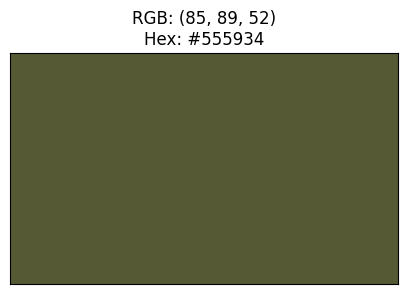

In [2]:
import matplotlib.pyplot as plt

# RGB Werte
r = 85  # Rot (0-255)
g = 89  # Grün (0-255)
b = 52   # Blau (0-255)

# Ein einfacher Plot
plt.figure(figsize=(5, 3))
plt.axhspan(0, 1, color=[r/255,g/255,b/255])  # plot mit Farbe füllen

# Achsen und Ränder entfernen
plt.xticks([])
plt.yticks([])
plt.margins(0)

# RGB und Hex Werte als Text hinzufügen
hex_color = f'#{r:02X}{g:02X}{b:02X}'
plt.title(f'RGB: ({r}, {g}, {b})\nHex: {hex_color}')

plt.show()

Mehrere Farben nebeneinander. Ändere die Werte und probiere aus, welche Farben entstehen:

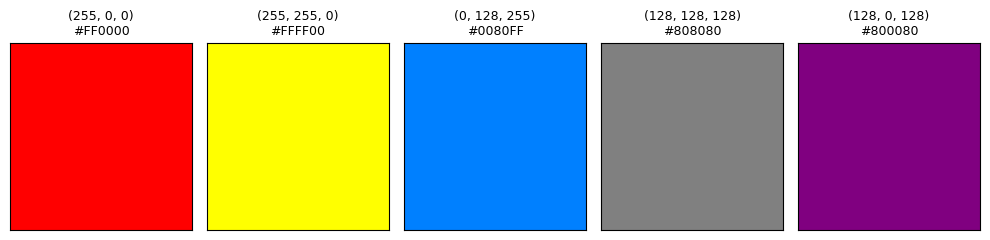

In [3]:
farben = [(255, 0, 0), (255, 255, 0), (0, 128, 255), (128, 128, 128), (128, 0, 128)]

fig, axes = plt.subplots(1, len(farben), figsize=(10, 2.5))
for ax, (r, g, b) in zip(axes, farben):
    ax.axhspan(0, 1, color=[r/255, g/255, b/255])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.margins(0)
    ax.set_title(f'({r}, {g}, {b})\n#{r:02X}{g:02X}{b:02X}', fontsize=9)
plt.tight_layout()
plt.show()

### 2. Digitalisierung von Audio

Töne werden als Schwingungslinie dargestellt. Die Schwingungslinie nennt man auch **Signal**.

- Je größer die **Amplitude** (der Ausschlag der Schwingung), desto **lauter** der Ton.
- Je enger die Schwingungslinie, desto **höher** der Ton. Die Anzahl der Schwingungen pro Sekunde heißt **Frequenz** und wird in Hertz (Hz) angegeben. Menschen hören etwa 20 Hz bis 20 000 Hz.

Sprache und Musik erzeugen kompliziertere Schwingungslinien als einzelne Töne.

Beim Digitalisieren wird das Signal in festen Zeitabständen gemessen (**abgetastet**):

<img src='./audio1.png'>

#### Die Fachbegriffe

| Begriff | Bedeutung | üblicher Wert |
|:--|:--|:--|
| **Samplingrate** (Abtastrate) | Wie oft wird das Signal pro Sekunde abgetastet? | 44,1 kHz = 44 100 Messwerte pro Sekunde |
| **Samplingtiefe** | Speicherplatz für einen Messwert. Die gemessenen Werte werden auf die möglichen Stufen gerundet. | 16 Bit, also $2^{16} = 65\,536$ Stufen |
| **Datenrate** | Datenmenge (in Bit), die in einer Sekunde entsteht | |
| **Datenmenge** | Datenmenge, die insgesamt entsteht | |

$$\text{Datenrate} = \text{Samplingrate} \cdot \text{Samplingtiefe}$$

$$\text{Datenmenge} = \text{Datenrate} \cdot \text{Dauer}$$

Bei **Stereo** werden zwei Kanäle (links und rechts) gespeichert, die Datenmenge verdoppelt sich.

#### Beispiel

Im Beispiel wird das Signal 12 mal pro Sekunde abgetastet. Die Samplingrate beträgt also 12 Hz. Zur Unterscheidung der Signalstärke stehen 8 verschiedene Werte zur Verfügung. Die Samplingtiefe ist also 3 Bit. Die Datenrate ist $12 \cdot 3 = 36$ Bit/s.

<img src='./audio.png' width='500'>

Die Messwerte (rote Punkte) werden auf ganze Zahlen von -3 bis 4 gerundet. Jeder Wert bekommt einen 3-Bit-Code, der tiefste Wert -3 bekommt `000`:

| Messwert | -3 | -2 | -1 | 0 | 1 | 2 | 3 | 4 |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| Code | `000` | `001` | `010` | `011` | `100` | `101` | `110` | `111` |

Die Audiodatei enthält folgende Nutzdaten (die Leerstellen sind zur Lesbarkeit eingefügt):

    000 111 110 100 100 000 001 010 110 100 010 001

Damit die Daten richtig interpretiert werden können, müssen in die Audiodatei noch Steuerdaten eingefügt werden:

    Wortbreite = 3
    Dauer = 1
    tiefster Wert = -3

Mit den Steuerdaten lassen sich die Messwerte zurückgewinnen: Messwert = Code + tiefster Wert.

In [4]:
nutzdaten = '000 111 110 100 100 000 001 010 110 100 010 001'
tiefster_wert = -3

messwerte = []
for code in nutzdaten.split():
    messwerte.append(int(code, 2) + tiefster_wert)
print(messwerte)

[-3, 4, 3, 1, 1, -3, -2, -1, 3, 1, -1, -2]


#### Beispiel: CD-Qualität

Eine Audio-CD speichert mit 44 100 Hz, 16 Bit und Stereo. Wie groß ist ein Musikstück von 3 Minuten?

$$\text{Datenrate} = 44\,100 \cdot 16 \cdot 2 = 1\,411\,200\ \text{Bit/s}$$

$$\text{Datenmenge} = 1\,411\,200\ \text{Bit/s} \cdot 180\ \text{s} = 254\,016\,000\ \text{Bit} \approx 31{,}8\ \text{MB}$$

Eine MP3-Datei desselben Stücks mit 192 kbit/s ist nur etwa 4,3 MB groß (siehe Abschnitt 4).

In [5]:
samplingrate = 44100     # Hz
samplingtiefe = 16       # Bit
kanaele = 2              # Stereo
dauer = 3 * 60           # Sekunden

datenrate = samplingrate * samplingtiefe * kanaele
datenmenge = datenrate * dauer
print(datenrate, 'Bit/s')
print(datenmenge / 8 / 1000**2, 'MB')

mp3 = 192_000 * dauer
print(mp3 / 8 / 1000**2, 'MB als MP3')

1411200 Bit/s
31.752 MB
4.32 MB als MP3


#### Samplingrate und Samplingtiefe ausprobieren

Die Grafik zeigt ein Signal (grau) und die gespeicherten Werte (rot). Ändere `samplingrate` und `samplingtiefe` und beobachte, wie gut die roten Punkte das Signal noch wiedergeben.

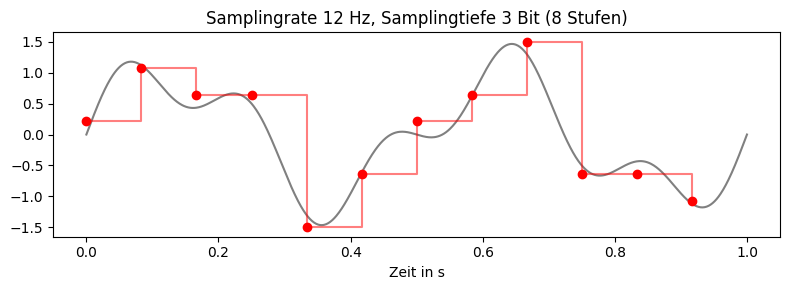

In [11]:
import numpy as np
import matplotlib.pyplot as plt

samplingrate = 12     # Messwerte pro Sekunde
samplingtiefe = 3     # Bit pro Messwert

t = np.linspace(0, 1, 1000)
signal = np.sin(2 * np.pi * 2 * t) + 0.5 * np.sin(2 * np.pi * 5 * t)

stufen = 2**samplingtiefe
tiefster, hoechster = -1.5, 1.5
t_mess = np.arange(0, 1, 1 / samplingrate)
s_mess = np.sin(2 * np.pi * 2 * t_mess) + 0.5 * np.sin(2 * np.pi * 5 * t_mess)
# auf die nächste der möglichen Stufen runden
schritt = (hoechster - tiefster) / (stufen - 1)
s_gerundet = tiefster + np.round((s_mess - tiefster) / schritt) * schritt

plt.figure(figsize=(8, 3))
plt.plot(t, signal, color='gray')
plt.step(t_mess, s_gerundet, where='post', color='red', alpha=0.5)
plt.plot(t_mess, s_gerundet, 'o', color='red')
plt.title(f'Samplingrate {samplingrate} Hz, Samplingtiefe {samplingtiefe} Bit ({stufen} Stufen)')
plt.xlabel('Zeit in s')
plt.tight_layout()
plt.show()

### 3. Datenreduktion

Digitale Bilder und Audiodateien bestehen aus vielen einzelnen Daten. Je mehr Daten gespeichert werden, desto größer wird die Datei. Um Speicherplatz zu sparen, kann man die Datenmenge reduzieren. Dabei gehen aber Informationen verloren.

| | wird verringert | Auswirkung |
|:--|:--|:--|
| **Bild** | **Auflösung** | Das Bild enthält weniger Pixel. Bilddetails gehen verloren, das Bild wirkt unschärfer. |
| | **Farbtiefe** | Es gibt weniger mögliche Farben. Farbverläufe und feine Farbunterschiede werden schlechter dargestellt. |
| **Audio** | **Samplingrate** | Es gibt weniger Messwerte, um die Schallwelle zu beschreiben. Schnelle Veränderungen im Ton werden nicht mehr genau erfasst: Hohe Töne gehen verloren, der Klang wird dumpf. |
| | **Samplingtiefe** | Lautstärken können nicht mehr so fein unterschieden werden. Es entstehen Rauschen und Verzerrungen, besonders bei leisen Stellen. |

Die Datenmenge ist proportional zu jeder dieser Größen: Halbiert man zum Beispiel die Samplingrate, halbiert sich auch die Datenmenge. Halbiert man Breite **und** Höhe eines Bildes, bleibt nur ein Viertel der Pixel übrig.

Im Programm oben kannst du die Auswirkungen auf ein Audiosignal ausprobieren.

### 4. Datenkompression

Bei der **Datenkompression** (auch: Datenkomprimierung) wird die Datenmenge verringert, indem die Daten geschickter gespeichert werden.

- **verlustfrei**: Die Originaldaten lassen sich aus den komprimierten Daten exakt wiederherstellen.
- **verlustbehaftet**: Die Originaldaten lassen sich nicht wiederherstellen. Dabei ist es unwesentlich, ob ein Qualitätsverlust wahrnehmbar ist oder nicht.

| Format / Anwendung       | Art             | Begründung                                                       |
| ------------------------ | --------------- | ---------------------------------------------------------------- |
| MP3 (Musik)              | verlustbehaftet | Für das Gehör kaum wahrnehmbare Frequenzanteile werden entfernt. |
| JPEG (Foto)              | verlustbehaftet | Kompromiss zwischen Dateigröße und Bildqualität.                 |
| PNG (Grafik, Screenshot) | verlustfrei     | Bilddaten müssen pixelgenau erhalten bleiben.                    |
| ZIP (Programmcode, Text) | verlustfrei     | Nach dem Entpacken muss exakt der Originaltext/-code vorliegen.  |

Programmcode und Textdokumente müssen *bit-genau* erhalten bleiben — schon ein verändertes Zeichen (z. B. ein Semikolon) kann Code unbrauchbar machen oder die Bedeutung eines Textes verändern. Bei Video und Musik nimmt der Mensch kleine Abweichungen dagegen kaum wahr, sodass zugunsten einer viel kleineren Datei ein geringer Qualitätsverlust akzeptiert wird — etwa beim Video-Streaming (begrenzte Bandbreite) oder bei Videotelefonie (Echtzeitübertragung, geringe Latenz wichtiger als volle Qualität).

Wie gut eine Kompression ist, gibt der **Kompressionsfaktor** an:

$$\text{Kompressionsfaktor} = \frac{\text{komprimierte Datenmenge}}{\text{ursprüngliche Datenmenge}}$$

Je kleiner der Kompressionsfaktor, desto stärker wurde komprimiert. Beim MP3-Beispiel oben: $\frac{4{,}3\ \text{MB}}{31{,}8\ \text{MB}} \approx 0{,}14$.

Achtung: Manchmal wird der Kompressionsfaktor auch anders herum als Verhältnis *ursprünglich : komprimiert* angegeben, z. B. „10:1“ (die Datei ist auf ein Zehntel geschrumpft). Das MP3-Beispiel mit 0,14 entspricht dann etwa 7:1, ein Kompressionsfaktor von 0,75 entspricht 4:3.

#### Lauflängenkodierung

Ein verlustfreies Kompressionsverfahren ist die **Lauflängenkodierung** (englisch *run-length encoding*, RLE). Sie wird vor allem bei Bildern eingesetzt, die nur wenige Farben enthalten.

Statt für jedes Pixel die Farbe zu notieren, wird die Farbe zusammen mit der Anzahl der Pixel, die diese Farbe haben, notiert. Falls es nur zwei Farben gibt, kann die Nennung der Farbe weggelassen werden, denn die Farbe wechselt nach jeder Lauflänge. Dann muss aber vereinbart werden, welches die Start-Farbe ist. Wir vereinbaren Weiß (1) als Start-Farbe.

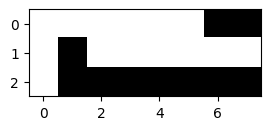

In [12]:
import numpy as np
import matplotlib.pyplot as plt

s = '111111001011111110000000'
fig = plt.figure(figsize=(3,2))
img = np.array(list(s), dtype=np.uint8).reshape(3, 8)   # aus dem String s wird ein numpy-array
plt.imshow(img, cmap='gray');

Beispiel: Das Bild ist 8 Pixel breit und 3 Pixel hoch. Die Pixel werden zeilenweise von links oben nach rechts unten gelesen.

**Schritt 1:** Ohne Lauflängenkodierung können wir die Farbinformation des Bildes so codieren (1 Bit pro Pixel):
```
111111001011111110000000
```

**Schritt 2:** Wir ermitteln die Folge der Lauflängen, also wie viele gleiche Pixel jeweils aufeinander folgen:
```
111111  00  1  0  1111111  0000000
   6     2  1  1     7        7
```

**Schritt 3:** Wir ermitteln, wie viel Bit wir für die Codierung der größten vorkommenden Zahl benötigen (hier 7, also 3 Bit), und codieren alle Zahlen mit dieser Bitanzahl:
```
110 010 001 001 111 111
```

Die gesamte Farbinformation wird also in der folgenden Bitfolge gespeichert:
```
110010001001111111
```

**Schritt 4:** Die Codierung wurde von 24 Bit auf 18 Bit reduziert.

$$\text{Kompressionsfaktor} = \frac{18}{24} = 0{,}75$$

Beginnt ein Bild mit einem schwarzen Pixel, ist die erste Lauflänge 0, denn die vereinbarte Start-Farbe ist Weiß.

Zum Dekodieren muss man außerdem wissen, mit wie vielen Bit jede Lauflänge codiert ist und wie breit das Bild ist. Auch das sind Steuerdaten, die in der Datei gespeichert werden.

##### Wann lohnt sich die Lauflängenkodierung?

Die Lauflängenkodierung spart nur dann Platz, wenn **lange Folgen gleicher Pixel** vorkommen. Wechselt die Farbe sehr oft, wird die codierte Bitfolge sogar **länger** als das Original:

Bei Fotos haben benachbarte Pixel fast nie exakt dieselbe Farbe. Deshalb benutzt man für Fotos andere Verfahren wie JPEG.